# 03 · Policies and the readiness frontier

> **Independent educational simulation. Not an airline system or an approved maintenance, airworthiness or dispatch tool.** Falcon Hub Airways is fictional; every airline number below is SIMULATED by this repo's code. Provenance tags: **REAL** (public data), **DERIVED** (computed by code), **ASSUMED** (a config planning assumption), **SIMULATED** (simulator output).

**Question.** How much AOG (aircraft-on-ground) time does better spares planning remove, at what capital, and how robust is the answer?

**Policies compared** (all frozen before the holdout):

* **P0 legacy:** static min/max from vendor quotes, a rotable float with no safety stock, almost everything at AUH;
* **P1 local optimised:** every station sizes its own stock (single-echelon), a deliberate straw man;
* **P2 network:** a pooled hub float plus outstation units only where the AOG transport time pays for them, with laterals and rebalancing;
* **I125 recommended:** P2 plus greedy capital additions, chosen on the selection seeds by a pre-stated rule.

Headline numbers are **holdout** (20 unseen seeds 1000–1019, weeks 104–155, paired common random numbers). Selection-seed numbers appear only as a consistency check. Total annual cost = holding + repair + logistics + expedite + AOG penalty (ASSUMED AED 15k/h narrowbody, 30k/h widebody). Capital is reported separately, never added.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))            # notebooks/_style.py
import numpy as np, pandas as pd, duckdb
import matplotlib.pyplot as plt
from _style import *                            # palette, ROOT, stamp(), aed_m(), load_json()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("project root:", ROOT)
ps = load_json("outputs/holdout/policy_summary.json")
sel = load_json("outputs/policies/selection_summary.json")
cen = ps["variants"]["central"]
print(ps["split"], "seeds", ps["seeds"][0], "-", ps["seeds"][-1], "|", ps["ci_method"])

project root: /Users/akashgajjar/grounded-no-more
holdout seeds 1000 - 1019 | 95% paired t over seeds; bootstrap check


## 1. P0 / P1 / P2 on the holdout

In [2]:
metrics = [("immediate_fill_rate", "fill", "{:.4f}"), ("aog_hours", "AOG h/yr", "{:,.0f}"), ("aog_events", "AOG events/yr", "{:.1f}"),
           ("spare_capital_aed", "capital AED M", "{:.2f}"), ("total_annual_cost_aed", "total cost AED M/yr", "{:.2f}"),
           ("expedite_cost_aed", "expedite AED M/yr", "{:.2f}")]
def cell(d, k, fmt):
    s = 1e6 if k.endswith("_aed") else 1
    return f"{fmt.format(d['mean']/s)} [{fmt.format(d['ci_lo']/s)}, {fmt.format(d['ci_hi']/s)}]"
tab = pd.DataFrame({lab: {p: cell(cen["policies"][p][k], k, f) for p in ["P0", "P1", "P2"]} for k, lab, f in metrics})
display(tab)
pair = pd.DataFrame({lab: {pr: cell(cen["paired"][pr][k], k, f) for pr in ["P1-P0", "P2-P0", "P2-P1"]} for k, lab, f in metrics})
pair["seeds with lower AOG"] = [cen["paired"][pr]["aog_hours"]["share_seeds_better"] for pr in pair.index]
print("Paired differences (mean [95% paired-t CI]):"); display(pair)

,fill,AOG h/yr,AOG events/yr,capital AED M,total cost AED M/yr,expedite AED M/yr
P0,"0.9542 [0.9521, 0.9562]","2,871 [2,459, 3,282]","86.2 [79.5, 93.0]","36.81 [36.19, 37.43]","86.00 [77.51, 94.49]","1.02 [0.90, 1.14]"
P1,"0.9817 [0.9798, 0.9836]","1,626 [1,243, 2,008]","26.8 [21.5, 32.1]","64.62 [64.09, 65.15]","63.08 [55.76, 70.40]","0.57 [0.47, 0.67]"
P2,"0.9796 [0.9774, 0.9818]","533 [419, 646]","20.4 [15.5, 25.4]","37.03 [36.51, 37.55]","36.85 [34.44, 39.26]","1.27 [1.13, 1.41]"


Paired differences (mean [95% paired-t CI]):


,fill,AOG h/yr,AOG events/yr,capital AED M,total cost AED M/yr,expedite AED M/yr,seeds with lower AOG
P1-P0,"0.0275 [0.0248, 0.0301]","-1,245 [-1,608, -883]","-59.5 [-66.4, -52.5]","27.81 [27.41, 28.21]","-22.91 [-30.33, -15.50]","-0.45 [-0.54, -0.36]",0.95
P2-P0,"0.0254 [0.0227, 0.0281]","-2,338 [-2,709, -1,967]","-65.8 [-72.7, -58.9]","0.22 [-0.17, 0.62]","-49.15 [-56.78, -41.53]","0.25 [0.13, 0.37]",1.00
P2-P1,"-0.0021 [-0.0034, -0.0008]","-1,093 [-1,415, -771]","-6.3 [-10.1, -2.6]","-27.59 [-27.73, -27.45]","-26.24 [-32.49, -19.99]","0.70 [0.59, 0.81]",1.00


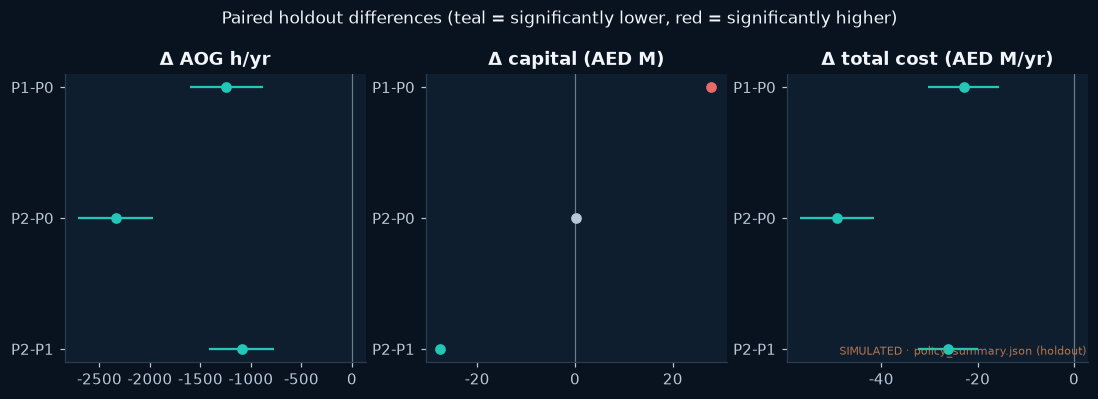

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, (k, lab, scale) in zip(axes, [("aog_hours", "Δ AOG h/yr", 1), ("spare_capital_aed", "Δ capital (AED M)", 1e6),
                                      ("total_annual_cost_aed", "Δ total cost (AED M/yr)", 1e6)]):
    prs = ["P1-P0", "P2-P0", "P2-P1"]
    for i, pr in enumerate(prs):
        d = cen["paired"][pr][k]
        col = TEAL if d["ci_hi"] < 0 else (RED if d["ci_lo"] > 0 else TITANIUM)
        ax.errorbar(d["mean"] / scale, i, xerr=[[(d["mean"] - d["ci_lo"]) / scale], [(d["ci_hi"] - d["mean"]) / scale]],
                    fmt="o", color=col, capsize=0, ms=6)
    ax.axvline(0, color=SLATE, lw=0.8); ax.set_yticks(range(3)); ax.set_yticklabels(prs); ax.invert_yaxis()
    ax.set_title(lab)
fig.suptitle("Paired holdout differences (teal = significantly lower, red = significantly higher)", color=ICE, y=1.05, fontsize=11)
stamp(axes[-1], "policy_summary.json (holdout)"); plt.show()

P2 removes about four-fifths of P0's material AOG hours for roughly the same capital. P1 buys some AOG reduction for about AED 28 M more capital, and P2 beats it on AOG, capital and cost. Every holdout seed favours P2 over P0.

### Selection vs holdout consistency

In [4]:
rows = []
for p in ["P0", "P1", "P2"]:
    for k in ["immediate_fill_rate", "aog_hours", "spare_capital_aed"]:
        h, s = cen["policies"][p][k], sel["variants"]["central"]["policies"][p][k]
        rows.append(dict(policy=p, metric=k, selection=s["mean"], holdout=h["mean"], holdout_ci=(round(h["ci_lo"], 4), round(h["ci_hi"], 4)),
                         selection_inside_holdout_ci=h["ci_lo"] <= s["mean"] <= h["ci_hi"]))
display(pd.DataFrame(rows).round(4))

,policy,metric,selection,holdout,holdout_ci,selection_inside_holdout_ci
0,P0,immediate_fill_rate,9.558000e-01,9.542000e-01,"(0.9521, 0.9562)",True
1,P0,aog_hours,2.937500e+03,2.870700e+03,"(2459.274, 3282.126)",True
2,P0,spare_capital_aed,3.623944e+07,3.680931e+07,"(36186552.3078, 37432077.1709)",True
3,P1,immediate_fill_rate,9.818000e-01,9.817000e-01,"(0.9798, 0.9836)",True
4,P1,aog_hours,1.677150e+03,1.625600e+03,"(1242.8186, 2008.3814)",True
5,P1,spare_capital_aed,6.432084e+07,6.462004e+07,"(64093069.3505, 65147003.4065)",True
6,P2,immediate_fill_rate,9.793000e-01,9.796000e-01,"(0.9774, 0.9818)",True
7,P2,aog_hours,4.280000e+02,5.327500e+02,"(419.1234, 646.3766)",True
8,P2,spare_capital_aed,3.667204e+07,3.703107e+07,"(36508875.2958, 37553265.5728)",True


For P0, P1 and P2, every selection mean above falls inside its holdout CI. The recommended point I125 is the exception (section 3), and the gap is reported as-is rather than tuned away.

## 2. Hub vs outstation

Where is the AOG? Holdout AOG hours by station and policy:

policy_id,P0,P1,P2
station,,,
AUH,1721.0,1565.0,371.0
LHR,206.0,7.0,26.0
FRA,172.0,8.0,13.0
CAI,185.0,17.0,33.0
JED,175.0,27.0,35.0
BOM,291.0,2.0,40.0
SIN,122.0,0.0,16.0


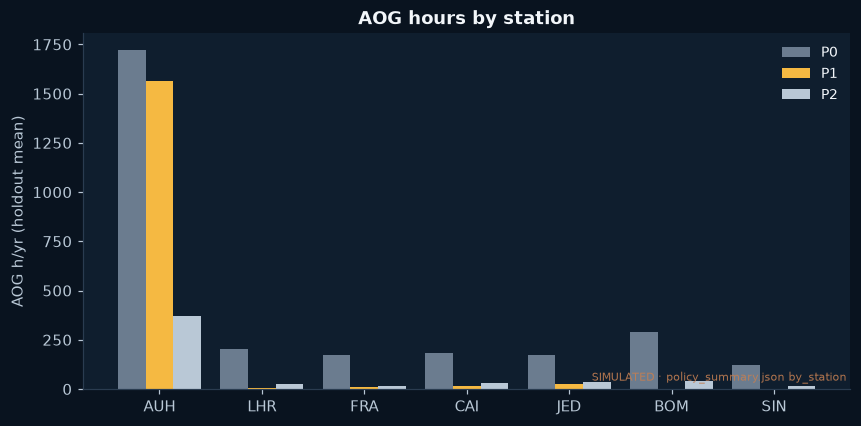

P0 share of AOG hours at the hub: 60%


In [5]:
bs = pd.DataFrame([r for r in ps["by_station"] if r["variant"] == "central"])
piv = bs.pivot(index="station", columns="policy_id", values="aog_hours").reindex(["AUH", "LHR", "FRA", "CAI", "JED", "BOM", "SIN"])
display(piv.round(0))
fig, ax = plt.subplots()
x = np.arange(len(piv)); wd = 0.27
for i, p in enumerate(["P0", "P1", "P2"]):
    ax.bar(x + (i - 1) * wd, piv[p], width=wd, color=POLICY_COLORS[p], label=p)
ax.set_xticks(x); ax.set_xticklabels(piv.index); ax.set(ylabel="AOG h/yr (holdout mean)", title="AOG hours by station")
ax.legend(frameon=False); stamp(ax, "policy_summary.json by_station"); plt.show()
print(f"P0 share of AOG hours at the hub: {piv.loc['AUH','P0'] / piv['P0'].sum():.0%}")

Most of P0's AOG sits at the **hub**, where deferred D3/D10 removals are rectified and the legacy float has no safety stock. P1 spreads stock to the outstations and nearly clears their AOG, but leaves the hub, which also supplies the outstations, no better. P2 pools the float at the hub and adds outstation units only where the AOG transport time pays for them. For this network, a marginal AED of rotable capital buys far more at the hub.

## 3. The readiness frontier and the recommended point

23 frozen candidates (P0/P1/P2, 16 re-optimised budget points, two 'P2 + greedy additions' points, a TAT lever and a combination) were simulated on the holdout. The recommendation rule was stated in advance and applied on the selection seeds: walk the lower convex hull of capital vs AOG, and stop where an extra AED 1 M saves fewer AOG hours than h\* = carrying % × AED 1 M ÷ (AED per AOG hour). It picked **I125**.

rule: h* = 9.42 AOG h per AED 1M (AED 21,238 per AOG h, carry 20%); recommended = I125


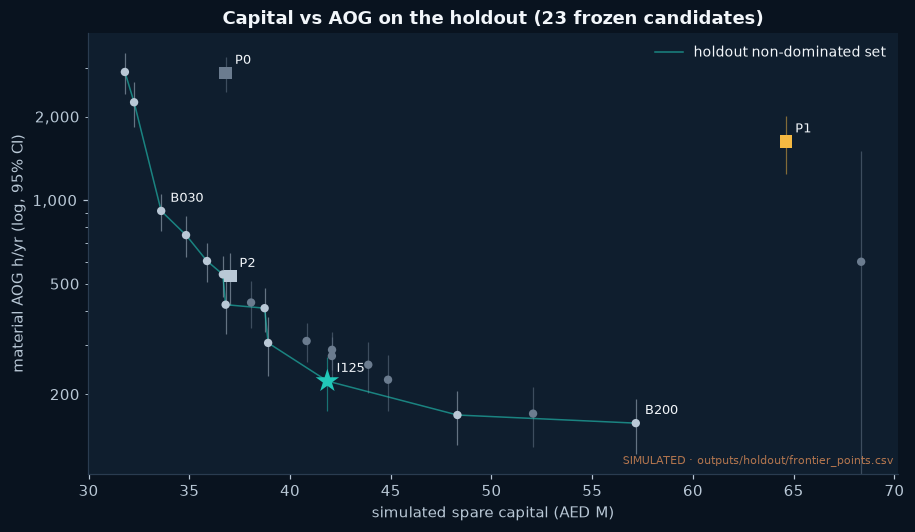

In [6]:
fp = pd.read_csv(ROOT / "outputs/holdout/frontier_points.csv").set_index("id")
fs = load_json("outputs/frontier/summary.json"); rec = fs["recommendation"]
site_fr = load_json("docs/data/frontier.json")
dom = {p["id"]: p["dominated"] for p in site_fr["points"]}
print(f"rule: h* = {rec['h_star_per_aed_1m']:.2f} AOG h per AED 1M (AED {rec['aed_per_aog_hour']:,.0f} per AOG h, carry {rec['carrying_pct']:.0%}); recommended = {rec['recommended']}")
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for pid, r in fp.iterrows():
    x, y = r.capital_mean / 1e6, r.aog_hours_mean
    if pid in ("P0", "P1", "P2"):
        col, mk, sz = POLICY_COLORS[pid], "s", 70
    elif pid == rec["recommended"]:
        col, mk, sz = TEAL, "*", 260
    else:
        col, mk, sz = (TITANIUM if not dom[pid] else SLATE), "o", 30
    ax.errorbar(x, y, yerr=[[y - r.aog_hours_lo], [r.aog_hours_hi - y]], fmt="none", ecolor=col, alpha=0.5, lw=0.8)
    ax.scatter(x, y, color=col, marker=mk, s=sz, zorder=3, edgecolor="none")
    if pid in ("P0", "P1", "P2", rec["recommended"], "B030", "B200"):
        ax.annotate(pid, (x, y), xytext=(6, 6), textcoords="offset points", color=ICE, fontsize=8.5)
nd = fp.loc[[k for k, v in dom.items() if not v]].sort_values("capital_mean")
ax.plot(nd.capital_mean / 1e6, nd.aog_hours_mean, color=TEAL, lw=1, alpha=0.6, label="holdout non-dominated set")
ax.set(yscale="log", xlabel="simulated spare capital (AED M)", ylabel="material AOG h/yr (log, 95% CI)",
       title="Capital vs AOG on the holdout (23 frozen candidates)")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.yaxis.set_minor_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}" if str(int(v))[0] in "25" else ""))
ax.legend(frameon=False, loc="upper right"); stamp(ax, "outputs/holdout/frontier_points.csv"); plt.show()

In [7]:
keep = ["P0", "P1", "P2", "B060", "B080", "I110", "I125", "B150", "B200", "LEV_TAT10_TOP8"]
ft = fp.loc[keep, ["capital_mean", "aog_hours_mean", "aog_hours_lo", "aog_hours_hi", "d_aog_hours_vs_base_mean",
                   "d_aog_hours_vs_base_lo", "d_aog_hours_vs_base_hi", "total_cost_mean", "fill_rate_mean", "aog_events_mean"]].copy()
for c in ["capital_mean", "total_cost_mean"]:
    ft[c] = ft[c] / 1e6
ft["dominated_on_holdout"] = [dom[k] for k in keep]
display(ft.round(2))
i = fp.loc["I125"]
print(f"I125 vs P2 (paired, holdout): ΔAOG {i.d_aog_hours_vs_base_mean:+.0f} h/yr [{i.d_aog_hours_vs_base_lo:+.0f}, {i.d_aog_hours_vs_base_hi:+.0f}], "
      f"Δcapital {aed_m(i.d_capital_vs_base_mean)}, Δtotal cost {aed_m(i.d_total_cost_vs_base_mean)} [{aed_m(i.d_total_cost_vs_base_lo)}, {aed_m(i.d_total_cost_vs_base_hi)}]")
for far in ["B150", "B200"]:
    f = fp.loc[far]
    print(f"I125 -> {far} on the holdout: {(i.aog_hours_mean - f.aog_hours_mean):.0f} h/yr fewer for {aed_m(f.capital_mean - i.capital_mean)} more "
          f"= {(i.aog_hours_mean - f.aog_hours_mean) / ((f.capital_mean - i.capital_mean) / 1e6):.1f} h per AED 1M (h* = {rec['h_star_per_aed_1m']:.1f})")
print("selection hull segments (h per AED 1M):", [(s["from"] + "→" + s["to"], round(s["h_per_aed_1m"], 1)) for s in rec["segments"]])

,capital_mean,aog_hours_mean,aog_hours_lo,aog_hours_hi,d_aog_hours_vs_base_mean,d_aog_hours_vs_base_lo,d_aog_hours_vs_base_hi,total_cost_mean,fill_rate_mean,aog_events_mean,dominated_on_holdout
id,,,,,,,,,,,
P0,36.81,2870.70,2459.27,3282.13,2337.95,1966.63,2709.27,86.00,0.95,86.25,True
P1,64.62,1625.60,1242.82,2008.38,1092.85,770.55,1415.15,63.08,0.98,26.80,True
P2,37.03,532.75,419.12,646.38,0.00,0.00,0.00,36.85,0.98,20.45,True
B060,36.67,540.10,448.80,631.40,7.35,-88.69,103.39,36.62,0.98,16.15,False
B080,38.74,408.15,334.45,481.85,-124.60,-202.83,-46.37,34.76,0.98,12.05,False
I110,38.91,306.00,232.50,379.50,-226.75,-304.62,-148.88,32.63,0.98,11.10,False
I125,41.85,223.00,174.18,271.82,-309.75,-407.74,-211.76,31.45,0.98,8.80,False
B150,48.31,168.25,131.17,205.33,-364.50,-465.61,-263.39,31.55,0.98,6.10,False
B200,57.16,157.30,122.16,192.44,-375.45,-479.79,-271.11,32.96,0.98,5.50,False


I125 vs P2 (paired, holdout): ΔAOG -310 h/yr [-408, -212], Δcapital AED 4.8M, Δtotal cost AED -5.4M [AED -7.4M, AED -3.4M]
I125 -> B150 on the holdout: 55 h/yr fewer for AED 6.5M more = 8.5 h per AED 1M (h* = 9.4)
I125 -> B200 on the holdout: 66 h/yr fewer for AED 15.3M more = 4.3 h per AED 1M (h* = 9.4)
selection hull segments (h per AED 1M): [('B015→B020', 1240.6), ('B020→B030', 995.0), ('B030→B050', 133.7), ('B050→B060', 76.7), ('B060→B080', 71.9), ('B080→I110', 64.7), ('I110→I125', 27.1), ('I125→B175', 1.4), ('B175→B200', 0.8)]


On the holdout, I125 holds about AED 41.9 M of capital and gives about 223 material AOG h/yr, against P0's about 2,871 h at AED 36.8 M. It is significantly better than P2 on paired seeds. Its holdout AOG is higher than on selection (118 h), and both are shown: the holdout is the headline. Beyond I125 the curve flattens. The next points buy fewer AOG hours per extra AED 1 M than the h\* threshold, so the rule's choice also holds on the holdout.

## 4. Levers: buy spares or cut repair TAT?

The optimiser compares, per rotable, buying 1–2 spares with paying the shop to cut 10 days of TAT (modelled, annual basis, at the P2 allocation; `outputs/frontier/levers.csv`).

buying 1 spare is cheaper per avoided AOG hour than a 10-day TAT cut for 28 of 32 rotables


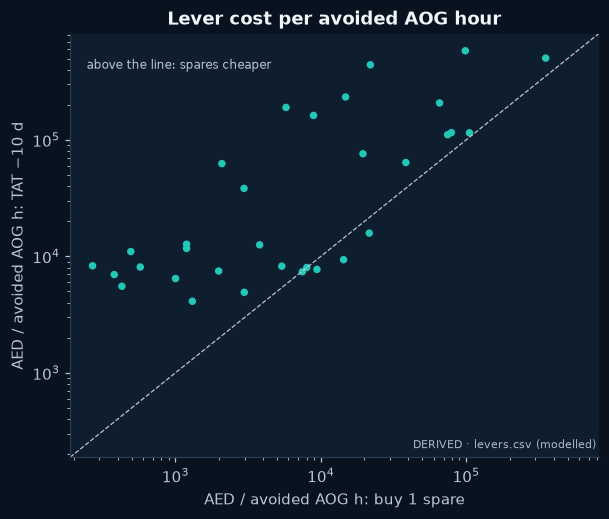

· GN-24-R003: cutting TAT (tat_cut_10d) avoids 5 AOG h/yr for AED 76,853/yr, vs 4 h/yr for AED 95,079/yr holding cost by buying 1 spares.
· GN-36-R024: buying 1 spares avoids 13 AOG h/yr for AED 25,265/yr, vs 12 h/yr for AED 87,152/yr by cutting TAT (tat_cut_10d).
· GN-34-R012: buying 1 spares avoids 11 AOG h/yr for AED 3,051/yr, vs 10 h/yr for AED 85,096/yr by cutting TAT (tat_cut_10d).
· GN-24-R017: buying 1 spares avoids 10 AOG h/yr for AED 3,610/yr, vs 9 h/yr for AED 62,955/yr by cutting TAT (tat_cut_10d).


In [8]:
lv = pd.read_csv(ROOT / "outputs/frontier/levers.csv")
w = lv.pivot_table(index="pn", columns="lever", values=["aog_hours_reduction", "annual_cost_aed"])
w.columns = [f"{a}|{b}" for a, b in w.columns]
w = w.dropna(subset=["aog_hours_reduction|buy_1", "aog_hours_reduction|tat_cut_10d"])
w["cost_per_h_buy1"] = w["annual_cost_aed|buy_1"] / w["aog_hours_reduction|buy_1"].where(w["aog_hours_reduction|buy_1"] > 0)
w["cost_per_h_tat"] = w["annual_cost_aed|tat_cut_10d"] / w["aog_hours_reduction|tat_cut_10d"].where(w["aog_hours_reduction|tat_cut_10d"] > 0)
w = w.dropna(subset=["cost_per_h_buy1", "cost_per_h_tat"])
print(f"buying 1 spare is cheaper per avoided AOG hour than a 10-day TAT cut for {(w.cost_per_h_buy1 < w.cost_per_h_tat).sum()} of {len(w)} rotables")
fig, ax = plt.subplots(figsize=(6.2, 5))
ax.scatter(w.cost_per_h_buy1, w.cost_per_h_tat, color=TEAL, s=24, edgecolor="none")
lim = [min(w.cost_per_h_buy1.min(), w.cost_per_h_tat.min()) * 0.7, max(w.cost_per_h_buy1.max(), w.cost_per_h_tat.max()) * 1.4]
ax.plot(lim, lim, color=TITANIUM, ls="--", lw=0.8)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="AED / avoided AOG h: buy 1 spare",
       ylabel="AED / avoided AOG h: TAT −10 d", title="Lever cost per avoided AOG hour")
ax.text(lim[0] * 1.3, lim[1] / 2, "above the line: spares cheaper", color=TITANIUM, fontsize=8)
stamp(ax, "levers.csv (modelled)", "DERIVED"); plt.show()
for s in fs["lever_findings"]["tat_vs_buy_1"][:4]:
    print("·", s)

Spares win on cheap rotables, and TAT cuts win only on expensive ones (e.g. GN-24-R003 at AED 475k a unit). Simulated on top of P2, TAT −10 d on the best 8 PNs removes about 110 AOG h/yr on the holdout (LEV_TAT10_TOP8 above). It is a real but second-order lever next to the rotable float.

## 5. Tornado: how sensitive is I125's advantage over P2?

Net annual benefit of I125 vs P2 (AOG penalty saved minus extra holding), paired over 20 selection seeds, as one assumption moves at a time.

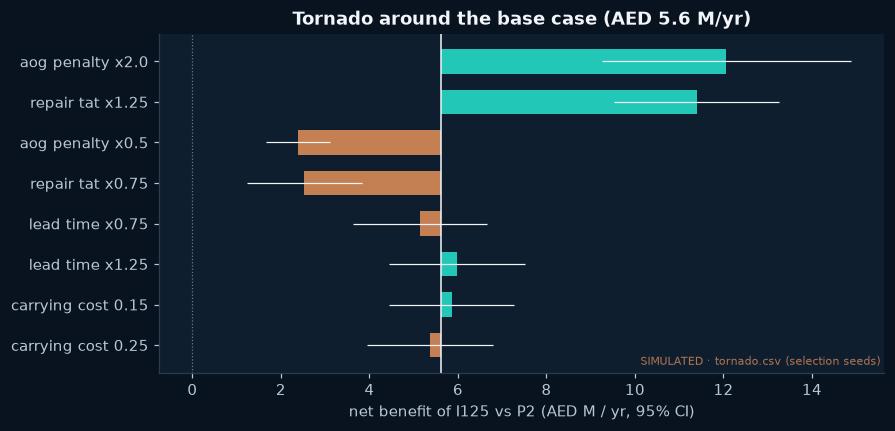

,label,net_benefit_mean,net_benefit_lo,net_benefit_hi,aog_reduction_mean,base_aog_hours,rec_aog_hours
2,aog penalty x2.0,12065126.0,9246597.0,14883656.0,310.0,428.0,118.0
6,repair tat x1.25,11393277.0,9523727.0,13262828.0,578.0,814.0,235.0
1,aog penalty x0.5,2384501.0,1661243.0,3107760.0,310.0,428.0,118.0
5,repair tat x0.75,2532278.0,1232267.0,3832290.0,160.0,252.0,92.0
7,lead time x0.75,5138420.0,3627874.0,6648966.0,296.0,403.0,108.0
8,lead time x1.25,5979841.0,4434095.0,7525587.0,327.0,612.0,285.0
3,carrying cost 0.15,5857749.0,4440444.0,7275054.0,310.0,428.0,118.0
4,carrying cost 0.25,5365004.0,3939723.0,6790285.0,310.0,428.0,118.0


In [9]:
tor = pd.read_csv(ROOT / "outputs/frontier/tornado.csv")
base = tor[tor.factor == "base case"].iloc[0]
t = tor[(tor.factor != "base case") & (~tor.factor.str.contains("expedite"))].copy()
t["label"] = t.factor.str.replace("_", " ") + " " + t.setting.astype(str)
t = t.iloc[np.argsort(-abs(t.net_benefit_mean - base.net_benefit_mean).values)]
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(t))
ax.barh(y, (t.net_benefit_mean - base.net_benefit_mean) / 1e6, left=base.net_benefit_mean / 1e6,
        color=[TEAL if v > base.net_benefit_mean else COPPER for v in t.net_benefit_mean], height=0.6)
ax.errorbar(t.net_benefit_mean / 1e6, y, xerr=[(t.net_benefit_mean - t.net_benefit_lo) / 1e6, (t.net_benefit_hi - t.net_benefit_mean) / 1e6],
            fmt="none", ecolor=ICE, lw=0.8)
ax.axvline(base.net_benefit_mean / 1e6, color=ICE, lw=1); ax.axvline(0, color=SLATE, lw=0.8, ls=":")
ax.set_yticks(y); ax.set_yticklabels(t.label); ax.invert_yaxis()
ax.set(xlabel="net benefit of I125 vs P2 (AED M / yr, 95% CI)", title=f"Tornado around the base case (AED {base.net_benefit_mean/1e6:.1f} M/yr)")
stamp(ax, "tornado.csv (selection seeds)"); plt.show()
display(t[["label", "net_benefit_mean", "net_benefit_lo", "net_benefit_hi", "aog_reduction_mean", "base_aog_hours", "rec_aog_hours"]].round(0))

I125's advantage stays positive and significant at every setting. It is smallest if repairs are 25 % faster and largest if they are 25 % slower. The AOG penalty scales it linearly, and the carrying rate barely matters.

## 6. Variant robustness: what if reliability is better or worse than the history suggests?

The same frozen candidates were run in a low-stress world (true MTBUR ×1.90) and a high-stress world (×0.85). The rule was re-applied per variant (selection seeds; `docs/data/frontier.json → variant_robustness`). The holdout P0/P1/P2 runs per variant follow.

In [10]:
vr = pd.DataFrame([dict(variant=v["variant"], P0_aog=v["P0"]["aog_hours"], P2_aog=v["P2"]["aog_hours"], I125_aog=v["I125"]["aog_hours"],
                         I125_capital_M=v["I125"]["capital_aed"] / 1e6, P2_capital_M=v["P2"]["capital_aed"] / 1e6,
                         I125_vs_P2_net_M=v["rec_vs_P2"]["net_benefit_aed"] / 1e6,
                         net_ci=tuple(round(x / 1e6, 2) for x in v["rec_vs_P2"]["net_benefit_ci"]), rule_picks=v["rule_recommends"])
                    for v in site_fr["variant_robustness"]])
display(vr.round(2))
hv = pd.DataFrame({v: {p: ps["variants"][v]["policies"][p]["aog_hours"]["mean"] for p in ["P0", "P1", "P2"]} for v in ["low_stress", "central", "high_stress"]}).T
print("Holdout AOG h/yr by variant (P1/P2 re-planned from each world's own history):"); display(hv.round(0))

,variant,P0_aog,P2_aog,I125_aog,I125_capital_M,P2_capital_M,I125_vs_P2_net_M,net_ci,rule_picks
0,low_stress,1327,38.35,34.9,40.57,35.13,-0.95,"(-1.17, -0.73)",P2
1,central,2938,428.00,117.8,41.60,36.67,5.61,"(4.19, 7.03)",I125
2,high_stress,3594,847.90,279.9,42.91,38.57,10.90,"(8.97, 12.84)",B125


Holdout AOG h/yr by variant (P1/P2 re-planned from each world's own history):


,P0,P1,P2
low_stress,1527.0,551.0,348.0
central,2871.0,1626.0,533.0
high_stress,4107.0,1986.0,543.0


The extra AED ~5 M that I125 holds over P2 is **insurance against a harsher reliability world**. In the low-stress world P2 alone is enough and I125 costs about AED 1 M/yr for no AOG gain. In the central and high-stress worlds it pays back AED 5.6 M and 10.9 M a year. Against P0, the network policies win in every world.

## 7. Dependence on the AOG desk

Every policy, P0 included, leans on the engine's AOG-desk emergency buy (an expedited rotable within at most 5 days at a 15 % premium), which in practice means access to an AOG exchange or loan market. Switching it off is the single most important sensitivity:

,AOG h/yr with AOG desk,AOG h/yr without
P0,2938.0,268505.0
P2,428.0,14404.0
I125,118.0,11226.0


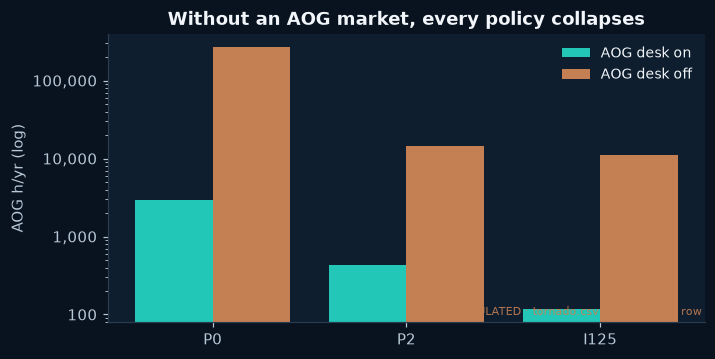

Every policy here, P0/P1/P2 included, leans on the engine's AOG-desk emergency buy (SIM-5: an expedited rotable arrives in at most 5 days at a 15% premium), which in practice means access to an AOG exchange/loan market; with that switched off, material AOG rises by one to two orders of magnitude for every policy (tornado row 'aog_desk_expedite off'), so the frontier is conditional on such a market existing for each PN.


In [11]:
off = tor[tor.factor.str.contains("expedite")].iloc[0]
d = pd.DataFrame({"AOG h/yr with AOG desk": {"P0": base.p0_base_aog_hours, "P2": base.base_aog_hours, "I125": base.rec_aog_hours},
                  "AOG h/yr without": {"P0": off.p0_base_aog_hours, "P2": off.base_aog_hours, "I125": off.rec_aog_hours}})
display(d.round(0))
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(3)
ax.bar(x - 0.2, d.iloc[:, 0], width=0.4, color=TEAL, label="AOG desk on")
ax.bar(x + 0.2, d.iloc[:, 1], width=0.4, color=COPPER, label="AOG desk off")
ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set(yscale="log", ylabel="AOG h/yr (log)", title="Without an AOG market, every policy collapses")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False); stamp(ax, "tornado.csv 'expedite off' row"); plt.show()
print(fs["aog_desk_dependence"])

## Summary

* **Network planning (P2) is the big win**: about −2,300 AOG h/yr against P0 on the holdout for roughly level capital, significant on every seed.
* **The recommended point I125** adds about AED 5 M of targeted rotable capital for a further significant AOG reduction. Its value depends on the reliability world, and the variant analysis is explicit about that.
* **The hub matters most.** Outstation positioning pays for D0 parts and cheap lines only.
* **Spares beat TAT cuts** except on expensive rotables.
* **Caveats:** the frontier is conditional on an AOG exchange market; the AOG penalty is an assumption (sensitivity-tested); everything is one simulated world (see `LIMITATIONS.md`).